In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

### Linear Regression Implemetion :

In [4]:
df=pd.read_csv("train.csv")

In [6]:
df.head(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [8]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [10]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [14]:
df.tail(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [16]:
df.sample()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
879,880,1,1,"Potter, Mrs. Thomas Jr (Lily Alexenia Wilson)",female,56.0,0,1,11767,83.1583,C50,C


In [18]:
df.ndim

2

In [20]:
df.size

10692

In [22]:
df.shape

(891, 12)

### Why do EDA

-Model Building 

-Analysis and Reporting 

-validate assumption

-Handling missing value

-Feature Engineering 

-Detecting Outliers 


## Univariate Analysis

In [23]:
#check age column

df["Age"]

0      22.0
1      38.0
2      26.0
3      35.0
4      35.0
       ... 
886    27.0
887    19.0
888     NaN
889    26.0
890    32.0
Name: Age, Length: 891, dtype: float64

In [24]:
df["Age"].isnull().sum()

np.int64(177)

In [26]:
percentage=df["Age"].isnull().sum()/len(df["Age"])*100

In [28]:
percentage

np.float64(19.865319865319865)

In [30]:
df["Age"].describe()

count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: Age, dtype: float64

<Axes: xlabel='Age', ylabel='Count'>

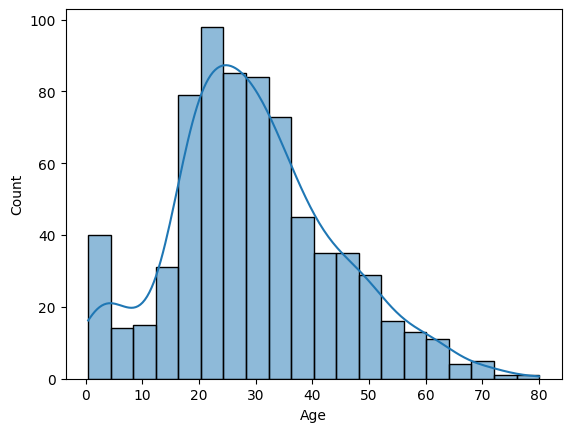

In [32]:
#check normal distribution

sns.histplot(x="Age",data=df,kde=True)

In [34]:
df["Age"].skew()

np.float64(0.38910778230082704)

<Axes: xlabel='Age'>

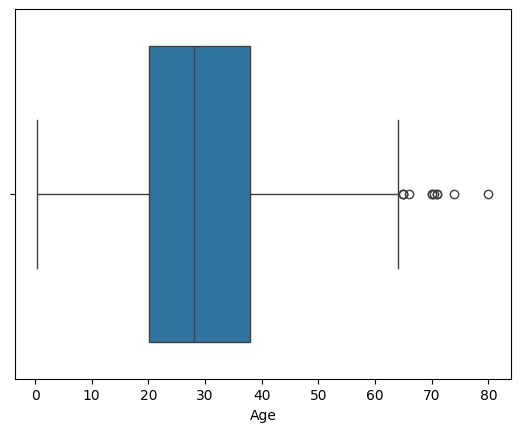

In [36]:
# check boxplot and z-score
sns.boxplot(x="Age",data=df)

In [37]:
#ub=upper bond, lb=lower bond
ub=df["Age"].mean()+3 *df["Age"].std()

In [39]:
ub

np.float64(73.27860964406095)

In [41]:
lb=df["Age"].mean()-3*df["Age"].std()

In [43]:
lb

np.float64(-13.88037434994331)

In [45]:
outliers=df["Age"] > ub

In [47]:
outliers

0      False
1      False
2      False
3      False
4      False
       ...  
886    False
887    False
888    False
889    False
890    False
Name: Age, Length: 891, dtype: bool

In [49]:
(df["Age"] > ub).sum()

np.int64(2)

In [51]:
df["Age"] < lb

0      False
1      False
2      False
3      False
4      False
       ...  
886    False
887    False
888    False
889    False
890    False
Name: Age, Length: 891, dtype: bool

In [53]:
(df["Age"] < lb).sum()

np.int64(0)

In [55]:
#this is concept of boolean masking
df[df["Age"] > ub]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
630,631,1,1,"Barkworth, Mr. Algernon Henry Wilson",male,80.0,0,0,27042,30.000,A23,S
851,852,0,3,"Svensson, Mr. Johan",male,74.0,0,0,347060,7.775,NaN,S


## Insight

### Age

##### Conclusion:

-Age is Normal Distribution

-20% of the values are missing

-There are some outliers

## #Fare

In [57]:
df["Fare"].isnull().sum()

np.int64(0)

<Axes: xlabel='Fare', ylabel='Count'>

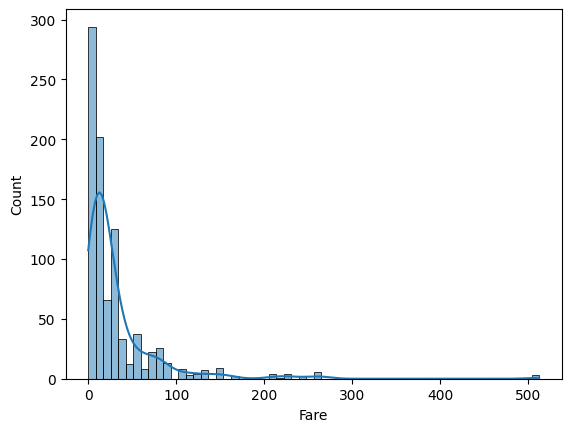

In [59]:
sns.histplot(x="Fare",data=df,kde=True)

In [61]:
df["Fare"].skew()

np.float64(4.787316519674893)

<Axes: xlabel='Fare'>

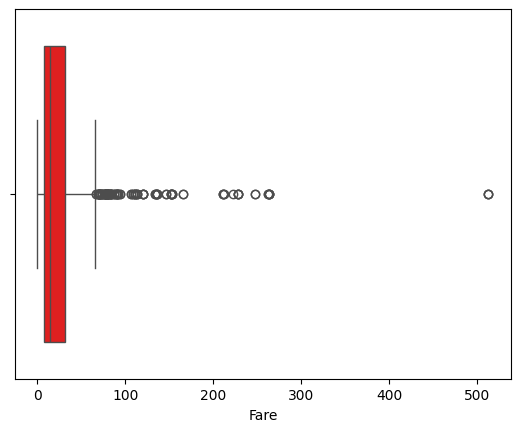

In [63]:
sns.boxplot(x="Fare",data=df,color="red")

In [65]:
df["Fare"].describe()

count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: Fare, dtype: float64

## Bivariate Analysis :

<Axes: xlabel='Age', ylabel='Fare'>

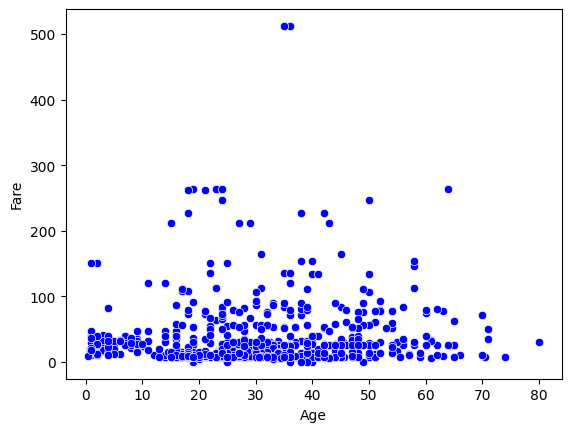

In [67]:
sns.scatterplot(data=df,x="Age",y="Fare",color="blue")

<Axes: xlabel='Age', ylabel='Fare'>

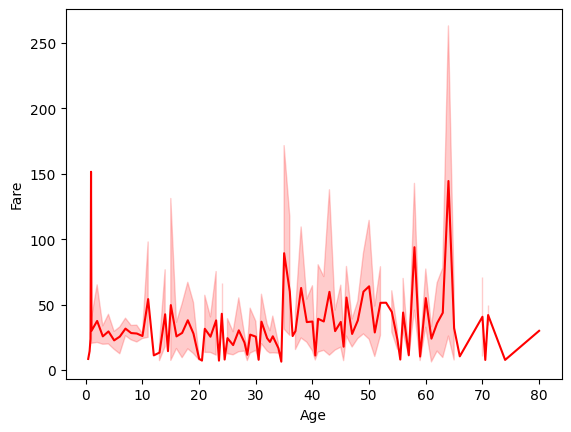

In [69]:
sns.lineplot(data=df,x="Age",y="Fare",color="red")

<Axes: xlabel='Age', ylabel='Fare'>

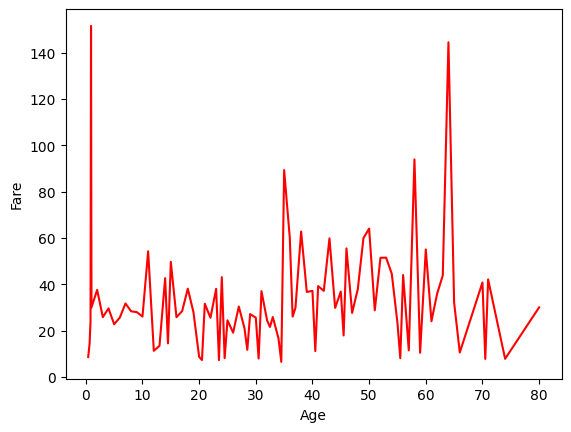

In [71]:
sns.lineplot(data=df,x="Age",y="Fare",color="red",errorbar=None)

<Axes: xlabel='Age', ylabel='Survived'>

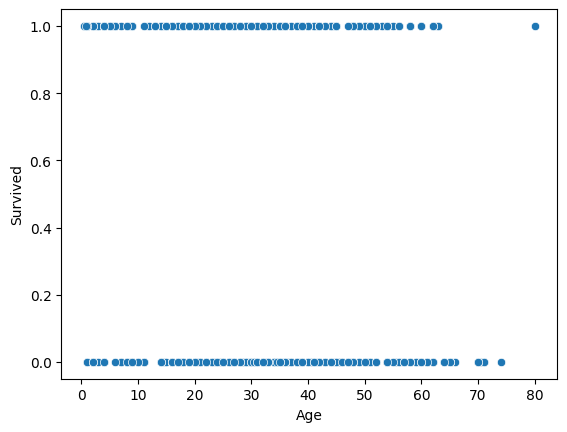

In [73]:
sns.scatterplot(data=df,x="Age",y="Survived")

<Axes: xlabel='Age', ylabel='Survived'>

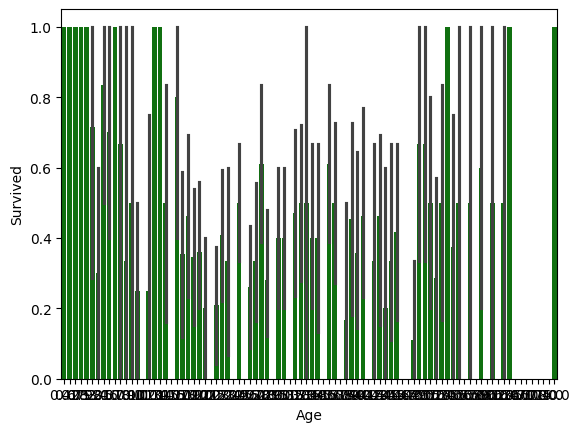

In [75]:
sns.barplot(x="Age",y="Survived",data=df,color="green")

<Axes: xlabel='Survived', ylabel='Age'>

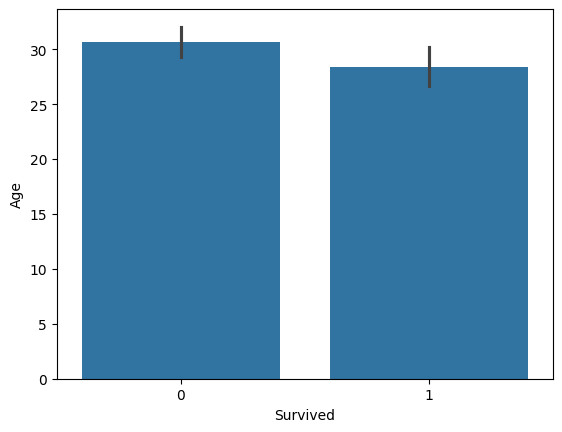

In [77]:
sns.barplot(data=df,x="Survived",y="Age")

### Fara & Age

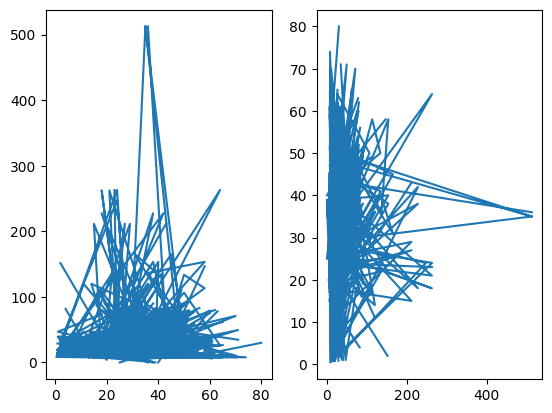

In [79]:
fig, axe = plt.subplots(1,2)
axe[0].plot(df["Age"],df["Fare"])
axe[1].plot(df["Fare"],df["Age"])

<Axes: xlabel='Sex', ylabel='count'>

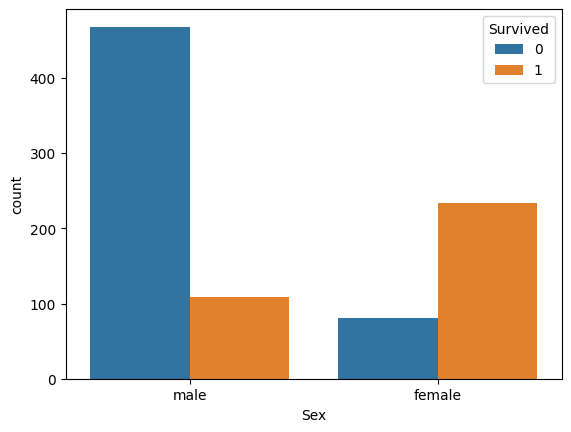

In [81]:
sns.countplot(data=df,x="Sex",hue="Survived")

<Axes: xlabel='Survived', ylabel='Age'>

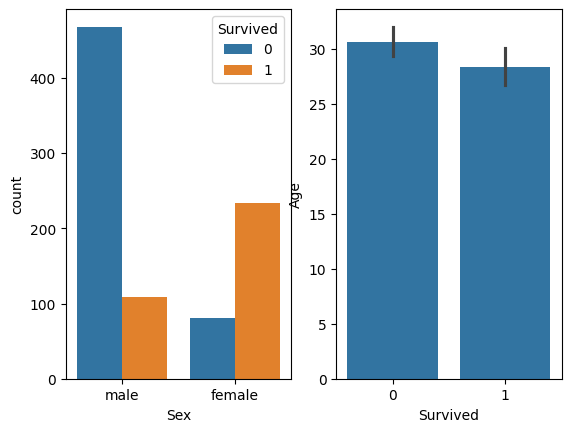

In [83]:
fig,axe=plt.subplots(1,2)
sns.countplot(data=df,x="Sex",hue="Survived",ax=axe[0])
sns.barplot(data=df,y="Age",x="Survived",ax=axe[1])


In [85]:
df.cov(numeric_only=True)

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
PassengerId,66231.000000,-0.626966,-7.561798,138.696504,-16.325843,-0.342697,161.883369
Survived,-0.626966,0.236772,-0.137703,-0.551296,-0.018954,0.032017,6.221787
Pclass,-7.561798,-0.137703,0.699015,-4.496004,0.076599,0.012429,-22.830196
Age,138.696504,-0.551296,-4.496004,211.019125,-4.163334,-2.344191,73.849030
SibSp,-16.325843,-0.018954,0.076599,-4.163334,1.216043,0.368739,8.748734
Parch,-0.342697,0.032017,0.012429,-2.344191,0.368739,0.649728,8.661052
Fare,161.883369,6.221787,-22.830196,73.849030,8.748734,8.661052,2469.436846


## Pandas Profiling

In [86]:
! pip install ydata-profiling

  Using cached ydata_profiling-4.18.4-py2.py3-none-any.whl.metadata (23 kB)
  Using cached visions-0.8.1-py3-none-any.whl.metadata (11 kB)
  Using cached phik-0.12.5-cp313-cp313-win_amd64.whl.metadata (5.6 kB)
  Using cached ImageHash-4.3.2-py2.py3-none-any.whl.metadata (8.4 kB)
  Using cached wordcloud-1.9.6-cp313-cp313-win_amd64.whl.metadata (3.5 kB)
Using cached ydata_profiling-4.18.4-py2.py3-none-any.whl (400 kB)
Using cached ImageHash-4.3.2-py2.py3-none-any.whl (296 kB)
Using cached phik-0.12.5-cp313-cp313-win_amd64.whl (678 kB)
Using cached visions-0.8.1-py3-none-any.whl (105 kB)
Using cached wordcloud-1.9.6-cp313-cp313-win_amd64.whl (306 kB)

   ---------------- ----------------------- 2/5 [visions]
   ---------------- ----------------------- 2/5 [visions]
   ------------------------ --------------- 3/5 [phik]
   -------------------------------- ------- 4/5 [ydata-profiling]
   -------------------------------- ------- 4/5 [ydata-profiling]
   -------------------------------- ---

In [88]:
from ydata_profiling import ProfileReport

In [90]:
report=ProfileReport(
    df,title="My Data Profiling Report",explorative=True
)


In [92]:
report.to_notebook_iframe()